In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os


plt.style.use('ggplot')

train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
submission_sample = pd.read_csv('sample_submission.csv')

print(f"Training Samples: {len(train_df)}")
print(f"Test Samples: {len(test_df)}")
display(train_df.head())

Training Samples: 3584
Test Samples: 3585


,image_id,type,count
0,39c668c5d00de5c470c005fb2561198404f1a2d4,coins,1
1,475ec66fb638f0ac8277f7260e022332c355a601,coins,1
2,159d16c88e6f095544e215b2cef5c8e0d128ad46,faces,4
3,f288d5754599d3716c2b7c2ba6731a05f74880ab,faces,2
4,58aa5fa93b0b26d2efe735567801022ea900589c,faces,3


/tmp/ipython-input-2734050170.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='type', data=train_df, palette='viridis')


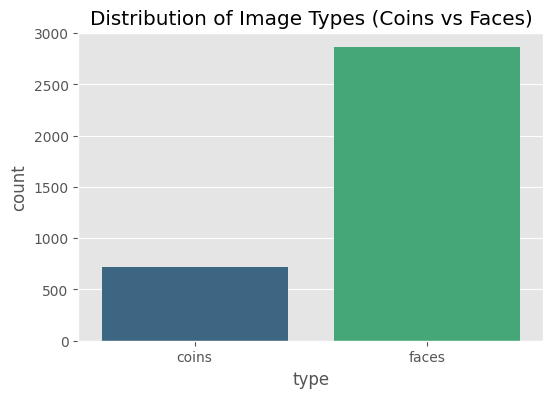

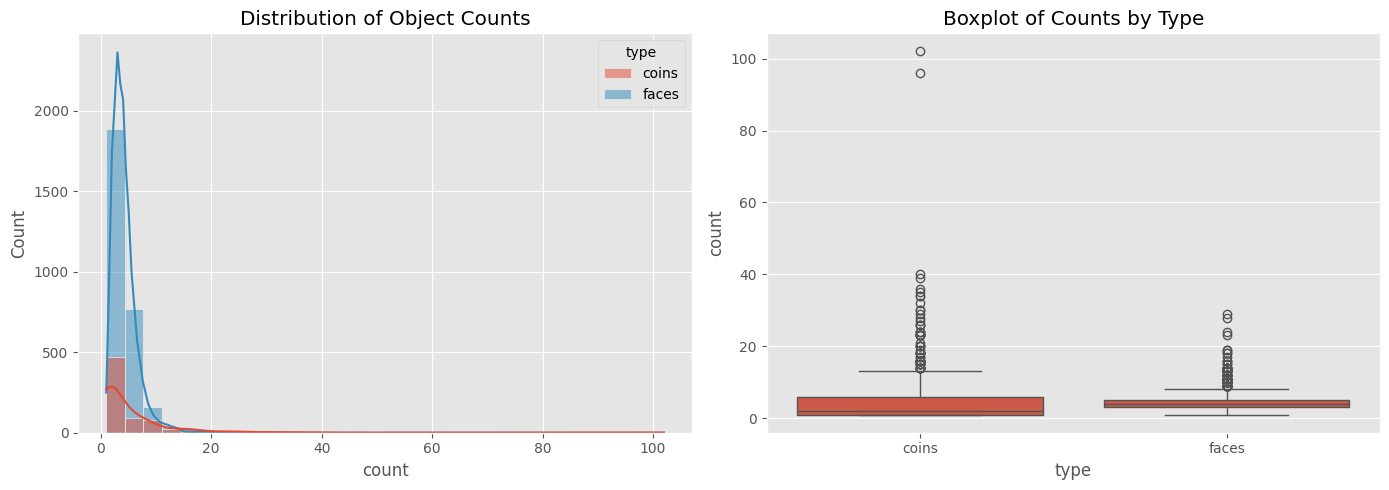

Number of images with 0 objects: 0 (0.00%)


In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='type', data=train_df, palette='viridis')
plt.title('Distribution of Image Types (Coins vs Faces)')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=train_df, x='count', hue='type', bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Object Counts')

sns.boxplot(x='type', y='count', data=train_df, ax=axes[1])
axes[1].set_title('Boxplot of Counts by Type')

plt.tight_layout()
plt.show()

zeros = train_df[train_df['count'] == 0]
print(f"Number of images with 0 objects: {len(zeros)} ({len(zeros)/len(train_df)*100:.2f}%)")

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

train_df = pd.read_csv('train.csv')

def get_features(row):
    path = f"train/{row['image_id']}.jpg"
    img = cv2.imread(path)

    if img is None:
        return [0, 0, 0, 0, 0, 0]

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 100, 200)

    mean_intensity = np.mean(gray)
    std_intensity = np.std(gray)
    edge_density = np.sum(edges) / (img.shape[0] * img.shape[1])

    red_mean = np.mean(img[:, :, 2])
    green_mean = np.mean(img[:, :, 1])
    blue_mean = np.mean(img[:, :, 0])

    return [mean_intensity, std_intensity, edge_density, red_mean, green_mean, blue_mean]

tqdm.pandas()
features_list = train_df.progress_apply(get_features, axis=1)
features_df = pd.DataFrame(features_list.tolist(), columns=['intensity', 'std', 'edges', 'red', 'green', 'blue'])

df_full = pd.concat([train_df, features_df], axis=1)
df_full = df_full[df_full['intensity'] > 0]

print("Feature Extraction Complete.")
display(df_full.head())

100%|██████████| 3584/3584 [00:26<00:00, 134.10it/s]

Feature Extraction Complete.


,image_id,type,count,intensity,std,edges,red,green,blue
0,39c668c5d00de5c470c005fb2561198404f1a2d4,coins,1,98.551556,46.733799,28.631778,103.753111,97.352089,91.134667
1,475ec66fb638f0ac8277f7260e022332c355a601,coins,1,89.196593,60.976163,53.262889,90.576919,90.405081,79.340637
2,159d16c88e6f095544e215b2cef5c8e0d128ad46,faces,4,157.322196,70.889347,38.696895,170.388464,151.680403,152.039680
3,f288d5754599d3716c2b7c2ba6731a05f74880ab,faces,2,93.081727,58.209789,22.212010,88.159918,93.919927,101.661028
4,58aa5fa93b0b26d2efe735567801022ea900589c,faces,3,129.722094,71.923896,20.304330,138.805223,127.693852,116.250028


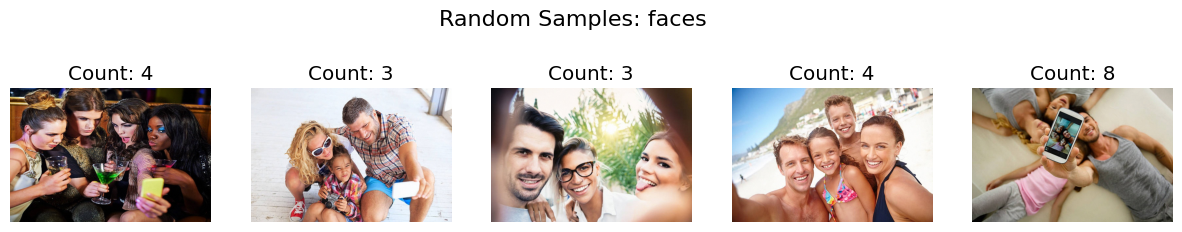

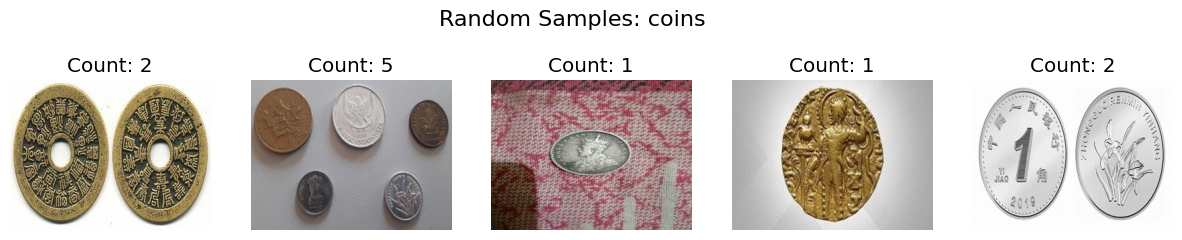

In [ ]:
def show_samples(df, type_name, num=5):
    subset = df[df['type'] == type_name].sample(num)
    plt.figure(figsize=(15, 3))
    for i, (_, row) in enumerate(subset.iterrows()):
        img = cv2.imread(f"train/{row['image_id']}.jpg")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, num, i + 1)
        plt.imshow(img)
        plt.title(f"Count: {row['count']}")
        plt.axis('off')
    plt.suptitle(f'Random Samples: {type_name}', fontsize=16)
    plt.show()

show_samples(train_df, 'faces')
show_samples(train_df, 'coins')

/tmp/ipython-input-380177168.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_full, x='type', y='count', palette='viridis')


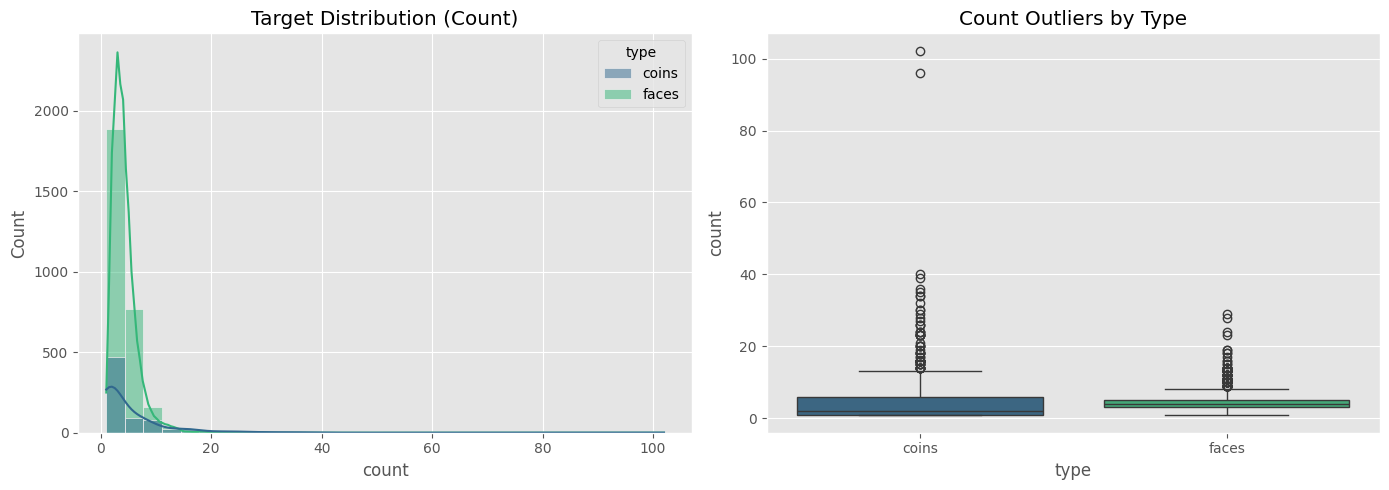

        count      mean       std  min  25%  50%  75%    max
type                                                        
coins   723.0  5.255878  7.834300  1.0  1.0  2.0  6.0  102.0
faces  2861.0  4.241524  2.338497  1.0  3.0  4.0  5.0   29.0


In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=df_full, x='count', hue='type', kde=True, bins=30, palette='viridis')
plt.title('Target Distribution (Count)')

plt.subplot(1, 2, 2)
sns.boxplot(data=df_full, x='type', y='count', palette='viridis')
plt.title('Count Outliers by Type')

plt.tight_layout()
plt.show()

print(df_full.groupby('type')['count'].describe())

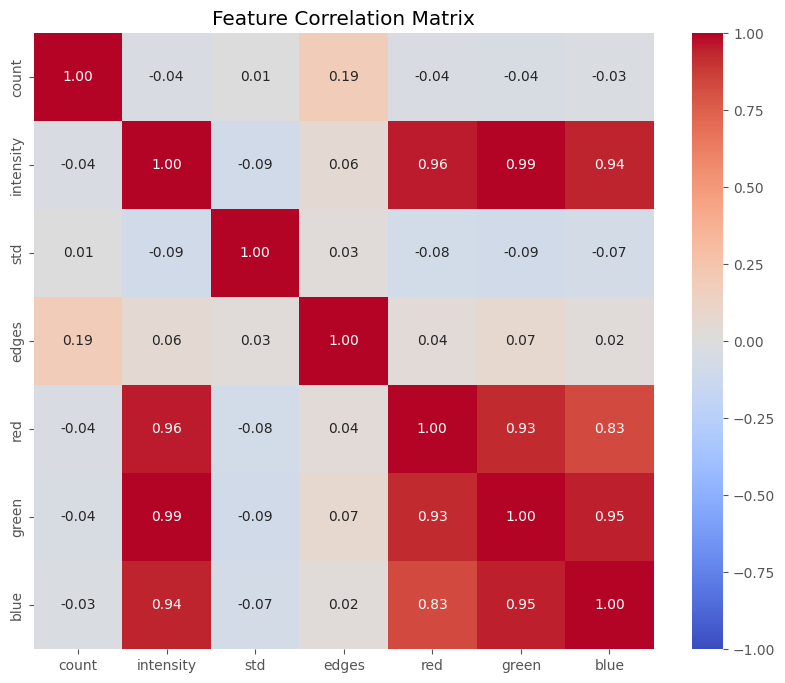

In [ ]:
plt.figure(figsize=(10, 8))
numeric_cols = ['count', 'intensity', 'std', 'edges', 'red', 'green', 'blue']
corr = df_full[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix')
plt.show()

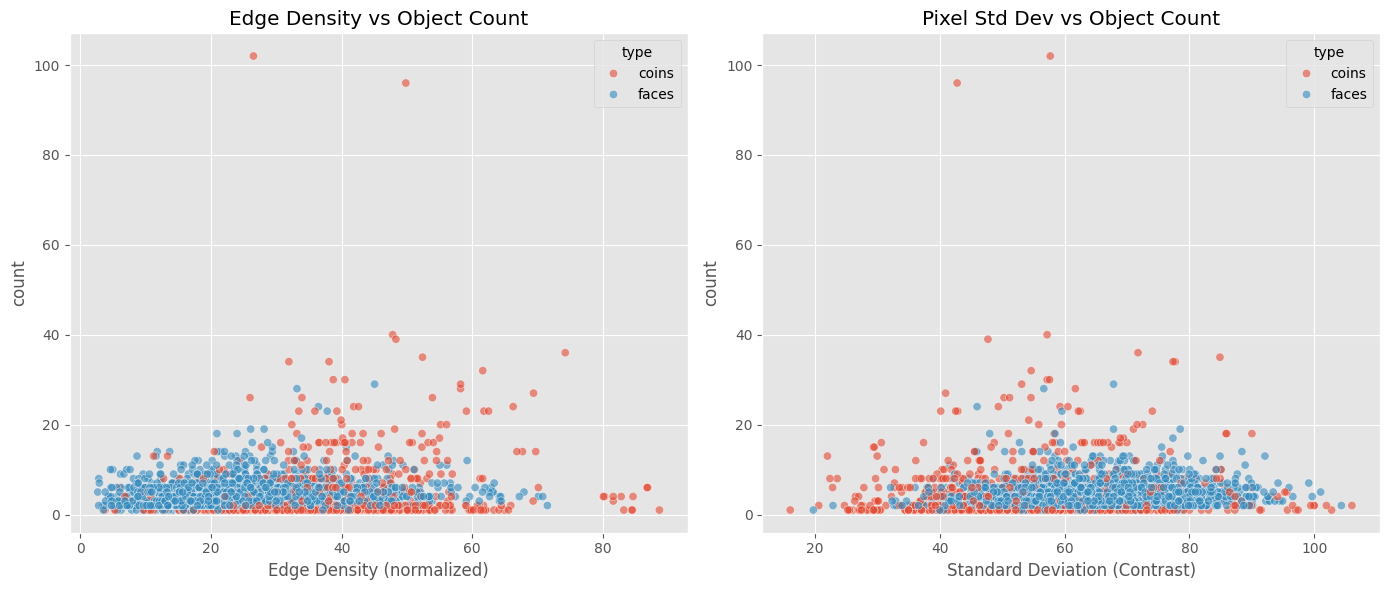

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_full, x='edges', y='count', hue='type', alpha=0.6)
plt.title('Edge Density vs Object Count')
plt.xlabel('Edge Density (normalized)')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_full, x='std', y='count', hue='type', alpha=0.6)
plt.title('Pixel Std Dev vs Object Count')
plt.xlabel('Standard Deviation (Contrast)')

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def extract_domain_features(row):
    path = f"train/{row['image_id']}.jpg"
    img = cv2.imread(path)
    if img is None:
        return [0, 0]

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces_detected = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
    num_faces_haar = len(faces_detected)

    blurred = cv2.medianBlur(gray, 5)

    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=1.2, minDist=30,
                               param1=50, param2=30, minRadius=10, maxRadius=100)

    num_circles_hough = 0
    if circles is not None:
        num_circles_hough = len(circles[0, :])

    return [num_faces_haar, num_circles_hough]

print("⚙️ Running Classical Detectors (Haar & Hough)...")
tqdm.pandas()
domain_features = train_df.progress_apply(extract_domain_features, axis=1)

domain_df = pd.DataFrame(domain_features.tolist(), columns=['haar_faces', 'hough_circles'])

full_analysis_df = pd.concat([train_df, domain_df], axis=1)

print("✅ Domain Feature Extraction Complete.")
display(full_analysis_df.head())

⚙️ Running Classical Detectors (Haar & Hough)...


100%|██████████| 3584/3584 [1:42:20<00:00,  1.71s/it]

✅ Domain Feature Extraction Complete.


,image_id,type,count,haar_faces,hough_circles
0,39c668c5d00de5c470c005fb2561198404f1a2d4,coins,1,0,35
1,475ec66fb638f0ac8277f7260e022332c355a601,coins,1,0,53
2,159d16c88e6f095544e215b2cef5c8e0d128ad46,faces,4,5,185
3,f288d5754599d3716c2b7c2ba6731a05f74880ab,faces,2,1,172
4,58aa5fa93b0b26d2efe735567801022ea900589c,faces,3,3,117


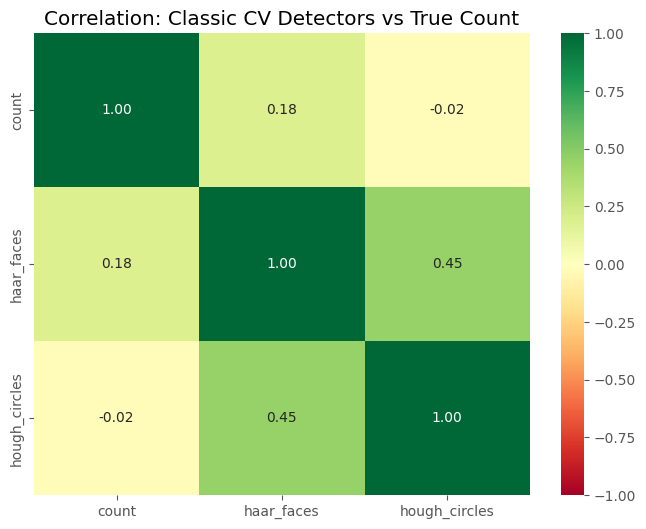

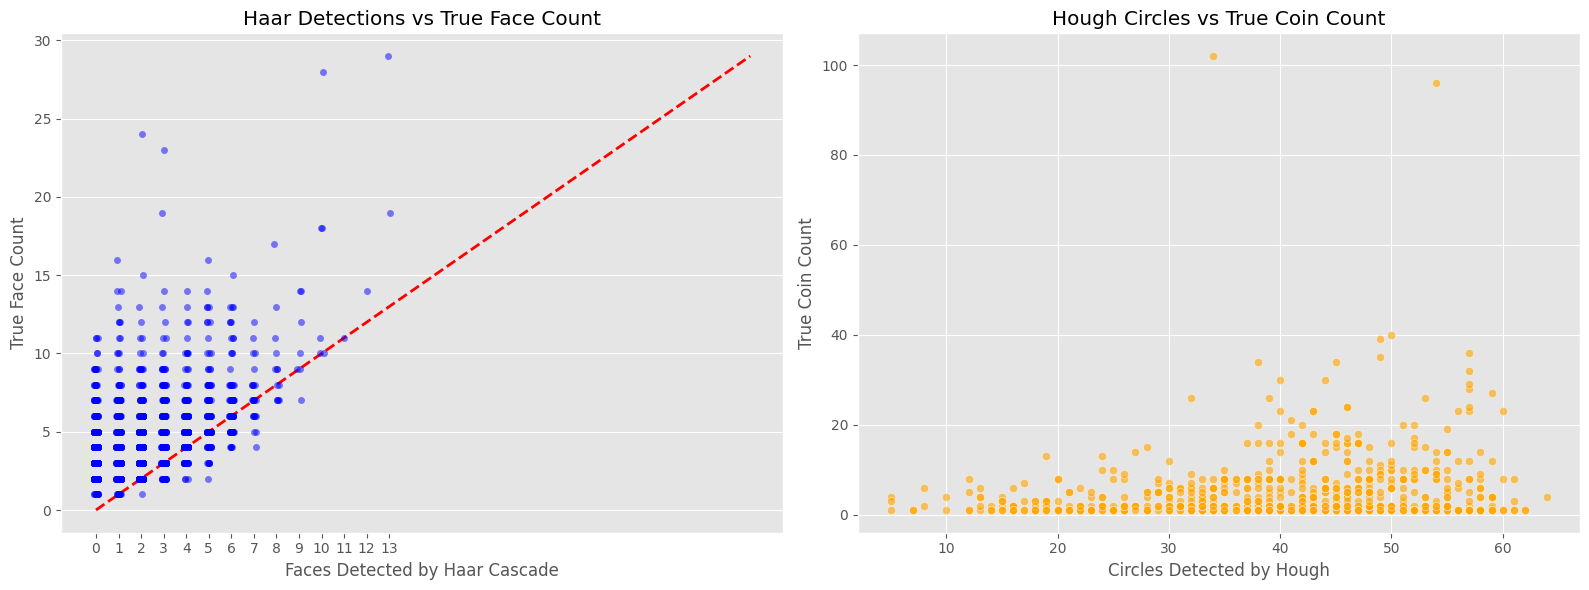

In [ ]:
new_corrs = full_analysis_df[['count', 'haar_faces', 'hough_circles']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(new_corrs, annot=True, cmap='RdYlGn', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation: Classic CV Detectors vs True Count')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.stripplot(x='haar_faces', y='count', data=full_analysis_df[full_analysis_df['type'] == 'faces'],
              ax=axes[0], alpha=0.5, jitter=True, color='blue')
axes[0].set_title('Haar Detections vs True Face Count')
axes[0].set_xlabel('Faces Detected by Haar Cascade')
axes[0].set_ylabel('True Face Count')
max_val = full_analysis_df[full_analysis_df['type'] == 'faces']['count'].max()
axes[0].plot([0, max_val], [0, max_val], 'r--', lw=2)

sns.scatterplot(x='hough_circles', y='count', data=full_analysis_df[full_analysis_df['type'] == 'coins'],
                ax=axes[1], alpha=0.6, color='orange')
axes[1].set_title('Hough Circles vs True Coin Count')
axes[1].set_xlabel('Circles Detected by Hough')
axes[1].set_ylabel('True Coin Count')

plt.tight_layout()
plt.show()